# 05 · Réplicas de Pedernales 2016 y la ley de Omori-Utsu

λ(t) = K / (t + c)^p, ajustada por máxima verosimilitud (Ogata, 1983) en el año siguiente al sismo y a ≤150 km del epicentro. Líneas base: Omori con p = 1 y decaimiento exponencial.

In [1]:
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display

from sismos import config, analisis, graficos
from sismos import gutenberg_richter as gr

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
ecuador = pd.read_parquet(config.CATALOGO_ECUADOR)
mundo = pd.read_parquet(config.CATALOGO_CINTURON)
historico = pd.read_parquet(config.CATALOGO_HISTORICO)
resultados = json.loads(config.RESULTADOS.read_text(encoding="utf-8"))
print(f"Ecuador: {len(ecuador):,} sismos · mundo M≥5: {len(mundo):,} · histórico M≥6: {len(historico):,}")

Ecuador: 3,214 sismos · mundo M≥5: 87,784 · histórico M≥6: 139


In [2]:
o = resultados['omori_pedernales']
pd.DataFrame([o['omori_utsu'], o['omori_p1'], o['exponencial']]).set_index('modelo').round(4)

,n,K,c,p,se_K,se_c,se_p,log_verosimilitud,aic,s,t,A,tau_dias
modelo,,,,,,,,,,,,,
Omori-Utsu,58,5.760,0.086,0.906,1.759,0.109,0.085,-75.346,156.692,0.0,365.0,NaN,NaN
Omori (p=1),58,7.855,0.227,1.000,1.251,0.151,NaN,-75.835,155.670,0.0,365.0,NaN,NaN
Exponencial,58,NaN,NaN,NaN,NaN,NaN,NaN,-116.475,236.949,NaN,NaN,0.979,59.379


In [3]:
print('Réplicas M≥2,5:', o['replicas_m25_150km_365d'], '· Mc:', o['mc'], '· sobre Mc:', o['n_sobre_mc'])
print('ΔAIC exponencial − Omori-Utsu:', round(o['delta_aic_exponencial_vs_utsu'], 1))
print('ΔAIC Omori p=1 − Omori-Utsu:', round(o['delta_aic_p1_vs_utsu'], 1))
print('Mayor réplica:', o['mayor_replica'], '· ley de Båth ΔM =', o['ley_bath_delta_m'])

Réplicas M≥2,5: 113 · Mc: 4.9 · sobre Mc: 58
ΔAIC exponencial − Omori-Utsu: 80.3
ΔAIC Omori p=1 − Omori-Utsu: -1.0
Mayor réplica: {'tiempo': '2016-05-18 16:46:43.860000+00:00', 'mw': 6.9, 'dias': 31.700079629629627, 'lugar': '24 km NW of Rosa Zarate, Ecuador'} · ley de Båth ΔM = 0.9


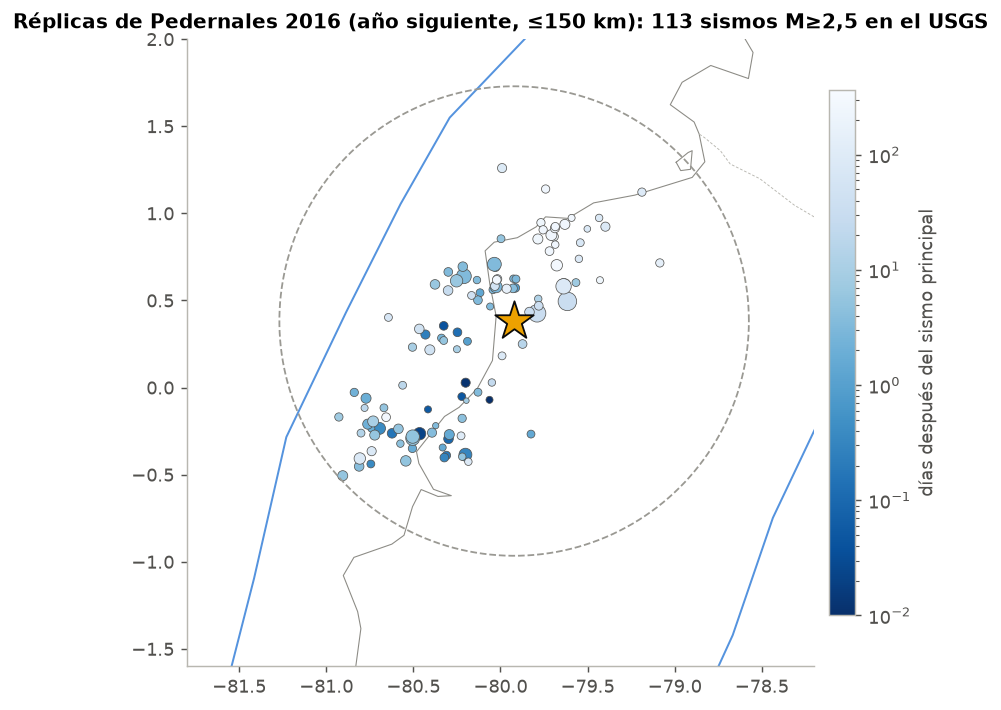

In [4]:
display(Image(config.FIGURAS / '12_mapa_replicas_pedernales.png'))

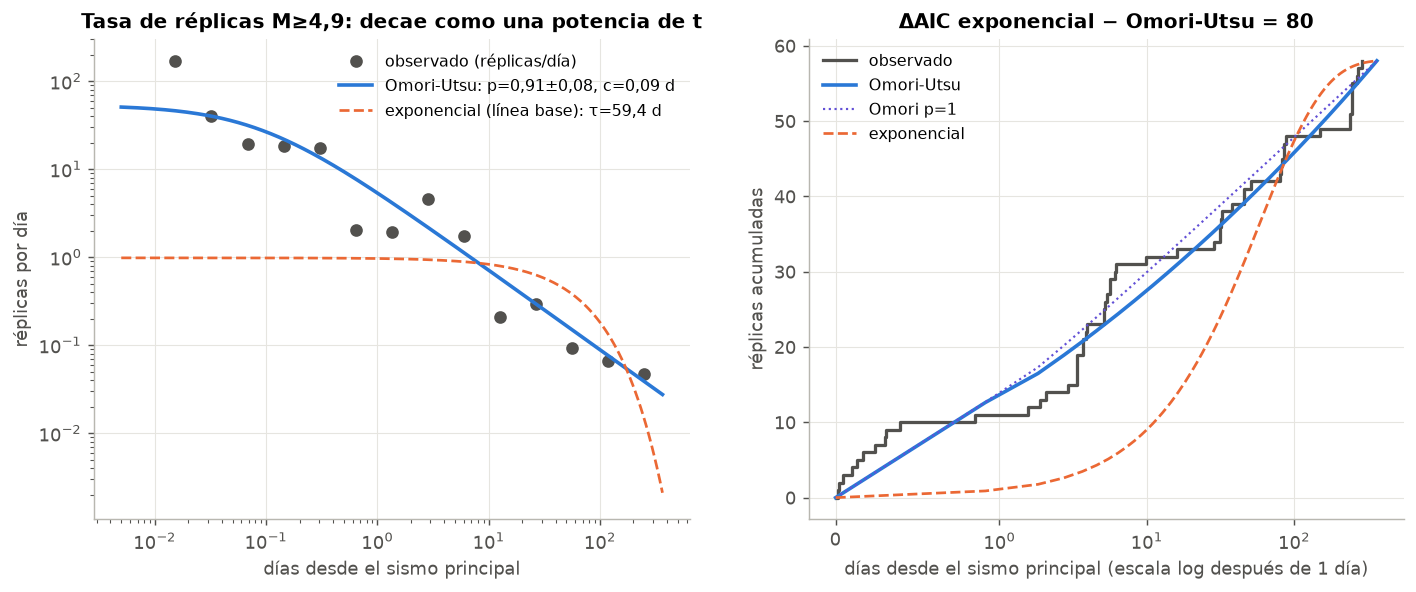

In [5]:
display(Image(config.FIGURAS / '13_omori_pedernales.png'))

Sensibilidad de p al umbral de magnitud:

In [6]:
pd.DataFrame(o['sensibilidad_mc']).round(3)

,mc,n,p,se_p,c,K
0,4.5,110,0.976,0.090,0.268,14.404
1,4.7,91,0.988,0.093,0.299,12.460
2,4.9,58,0.906,0.085,0.086,5.760
3,5.0,44,0.920,0.118,0.128,4.666
4,5.2,26,1.131,0.207,1.095,6.459


**Lectura:** p ≈ 1 (no se distingue de la ley de Omori original), la mitad de las réplicas llega en las primeras semanas y el decaimiento exponencial queda descartado por mucho. Con solo las réplicas que ve la red mundial (M≳4,5) la precisión es limitada; el catálogo local del IG-EPN tiene miles de réplicas más pequeñas.